URL DATASET
                         url  label
0     https://www.google.com      0
1  https://www.microsoft.com      0
2     https://www.amazon.com      0
3      https://www.apple.com      0
4  https://www.wikipedia.org      0

Total URLs: 40
Legitimate URLs: 20
Malicious URLs: 20

EXTRACTED FEATURES
   url_length  num_dots  num_hyphens  num_slashes  num_at  num_question  \
0          22         2            0            2       0             0   
1          25         2            0            2       0             0   
2          22         2            0            2       0             0   
3          21         2            0            2       0             0   
4          25         2            0            2       0             0   

   num_equals  num_percent  num_digits  https  suspicious_keyword  
0           0            0           0      1                   0  
1           0            0           0      1                   0  
2           0            0           0    

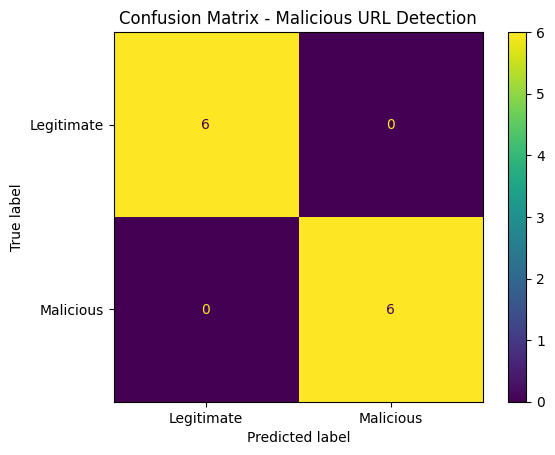


TEST PREDICTIONS
                                   URL     Actual  Predicted
                 https://www.wipro.com Legitimate Legitimate
               https://www.netflix.com Legitimate Legitimate
      http://login-security-verify.com  Malicious  Malicious
             https://www.wikipedia.org Legitimate Legitimate
          http://secure-bank-login.net  Malicious  Malicious
          http://login-confirmation.tk  Malicious  Malicious
     http://verify-payment-account.com  Malicious  Malicious
              https://www.linkedin.com Legitimate Legitimate
      https://www.jainuniversity.ac.in Legitimate Legitimate
http://paypal-account-verify.com/login  Malicious  Malicious
       http://win-prize-free.com/claim  Malicious  Malicious
              https://www.flipkart.com Legitimate Legitimate

NEW URL PREDICTION
URL: https://www.google.com
Prediction: LEGITIMATE
Legitimate Probability: 97.28 %
Malicious Probability: 2.72 %

NEW URL PREDICTION
URL: http://secure-login-verify-acco

In [1]:
# Experiment 4: Build a logistic regression model to classify URLs as either legitimate or malicious. 
# ============================================================
# MACHINE LEARNING IN CYBERSECURITY
# Logistic Regression for Malicious URL Detection
# ============================================================

# 1. Import Libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 2. Create Synthetic URL Dataset
# ============================================================

legitimate_urls = [
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.amazon.com",
    "https://www.apple.com",
    "https://www.wikipedia.org",
    "https://www.github.com",
    "https://www.linkedin.com",
    "https://www.netflix.com",
    "https://www.python.org",
    "https://www.ibm.com",
    "https://www.jainuniversity.ac.in",
    "https://www.amazon.in",
    "https://www.flipkart.com",
    "https://www.infosys.com",
    "https://www.wipro.com",
    "https://www.oracle.com",
    "https://www.adobe.com",
    "https://www.cisco.com",
    "https://www.samsung.com",
    "https://www.intel.com"
]

malicious_urls = [
    "http://login-security-verify.com",
    "http://paypal-account-verify.com/login",
    "http://secure-login-update.net",
    "http://banking-security-alert.com",
    "http://free-gift-winner.com/claim",
    "http://account-verification.xyz/login",
    "http://update-password-security.com",
    "http://verify-account-now.net",
    "http://login-confirmation.tk",
    "http://secure-paypal-login.ml",
    "http://bank-alert-verify.xyz",
    "http://win-prize-free.com/claim",
    "http://password-reset-confirm.net",
    "http://security-check-account.com",
    "http://login-verify-user.xyz",
    "http://free-money-winner.com/claim",
    "http://account-update-required.xyz",
    "http://secure-bank-login.net",
    "http://verify-payment-account.com",
    "http://urgent-security-check.xyz"
]

# Combine URLs
urls = legitimate_urls + malicious_urls

# 0 = Legitimate
# 1 = Malicious
labels = (
    [0] * len(legitimate_urls) +
    [1] * len(malicious_urls)
)

df = pd.DataFrame({
    "url": urls,
    "label": labels
})

print("=" * 60)
print("URL DATASET")
print("=" * 60)
print(df.head())
print("\nTotal URLs:", len(df))
print("Legitimate URLs:", sum(df["label"] == 0))
print("Malicious URLs:", sum(df["label"] == 1))


# ============================================================
# 3. Feature Extraction
# ============================================================

def extract_features(url):

    features = {
        "url_length": len(url),

        "num_dots": url.count("."),

        "num_hyphens": url.count("-"),

        "num_slashes": url.count("/"),

        "num_at": url.count("@"),

        "num_question": url.count("?"),

        "num_equals": url.count("="),

        "num_percent": url.count("%"),

        "num_digits": sum(c.isdigit() for c in url),

        "https": 1 if url.startswith("https") else 0,

        "suspicious_keyword": 1 if re.search(
            r"(login|verify|secure|account|update|"
            r"password|bank|winner|free|confirm|"
            r"payment|urgent)",
            url.lower()
        ) else 0
    }

    return features


# Extract features from every URL
feature_data = df["url"].apply(extract_features)

X = pd.DataFrame(feature_data.tolist())

y = df["label"]


print("\n" + "=" * 60)
print("EXTRACTED FEATURES")
print("=" * 60)

print(X.head())

print("\nFeature names:")
print(list(X.columns))


# ============================================================
# 4. Split Dataset into Training and Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 5. Feature Scaling
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# ============================================================
# 6. Train Logistic Regression Model
# ============================================================

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(X_train_scaled, y_train)

print("\n" + "=" * 60)
print("MODEL TRAINING")
print("=" * 60)

print("Logistic Regression model trained successfully!")


# ============================================================
# 7. Make Predictions
# ============================================================

y_pred = model.predict(X_test_scaled)

y_probability = model.predict_proba(X_test_scaled)


# ============================================================
# 8. Model Evaluation
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)


print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision * 100, 2), "%")
print("Recall    :", round(recall * 100, 2), "%")
print("F1-Score  :", round(f1 * 100, 2), "%")


# ============================================================
# 9. Classification Report
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Malicious"]
    )
)


# ============================================================
# 10. Confusion Matrix
# ============================================================

cm = confusion_matrix(y_test, y_pred)

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Malicious"]
)

disp.plot()

plt.title("Confusion Matrix - Malicious URL Detection")
plt.show()


# ============================================================
# 11. Display Test Results
# ============================================================

results = pd.DataFrame({
    "URL": df.loc[X_test.index, "url"],
    "Actual": y_test,
    "Predicted": y_pred
})

results["Actual"] = results["Actual"].map({
    0: "Legitimate",
    1: "Malicious"
})

results["Predicted"] = results["Predicted"].map({
    0: "Legitimate",
    1: "Malicious"
})

print("\n" + "=" * 60)
print("TEST PREDICTIONS")
print("=" * 60)

print(results.to_string(index=False))


# ============================================================
# 12. Function to Predict a New URL
# ============================================================

def predict_url(url):

    # Extract features
    features = extract_features(url)

    # Convert to DataFrame
    new_data = pd.DataFrame([features])

    # Scale features
    new_data_scaled = scaler.transform(new_data)

    # Prediction
    prediction = model.predict(new_data_scaled)[0]

    # Probability
    probability = model.predict_proba(new_data_scaled)[0]

    print("\n" + "=" * 60)
    print("NEW URL PREDICTION")
    print("=" * 60)

    print("URL:", url)

    if prediction == 0:
        print("Prediction: LEGITIMATE")
    else:
        print("Prediction: MALICIOUS")

    print(
        "Legitimate Probability:",
        round(probability[0] * 100, 2),
        "%"
    )

    print(
        "Malicious Probability:",
        round(probability[1] * 100, 2),
        "%"
    )


# ============================================================
# 13. Test New URLs
# ============================================================

predict_url("https://www.google.com")

predict_url("http://secure-login-verify-account.com")

predict_url("http://free-money-winner.com/claim")

predict_url("https://www.github.com")